In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from rink import plot_rink

## 1.

In [2]:
events = pd.read_excel('NHL-playoffs-2026.xlsx')

In [3]:
print(events.shape)
print(events.columns)

(29710, 39)
Index(['Unnamed: 0', 'Dataset', 'Game ID', 'Date', 'Away Team', 'Home Team',
       'Cumulated Away Score', 'Cumulated Home Score', 'Period',
       'Elapsed Time', 'Remaining Time', 'Play ID', 'Play Length', 'Play Type',
       'Play Subtype', 'Play Zone', 'Team Making the Play',
       'Player in the Event #1', 'Player in the Event #2',
       'Player in the Event #3', 'X Coordinate on the Ice Rink',
       'Y Coordinate on the Ice Rink', '# of Away Team's Players on the Ice',
       '# of Home Team's Players on the Ice',
       'Away Team's Player on the Ice #1', 'Away Team's Player on the Ice #2',
       'Away Team's Player on the Ice #3', 'Away Team's Player on the Ice #4',
       'Away Team's Player on the Ice #5', 'Away Team's Player on the Ice #6',
       'Away Team's Goalie', 'Home Team's Player on the Ice #1',
       'Home Team's Player on the Ice #2', 'Home Team's Player on the Ice #3',
       'Home Team's Player on the Ice #4', 'Home Team's Player on the Ice #5'

In [4]:
events = events.drop(columns=events.columns[0])

In [5]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Всего 38 столбцов, 29710 строк.

## 2.

In [6]:
def outcome(p):
    if p <= 3:
        return "Final"
    else:
        return "Final/OT" if p == 4 else f"Final/{p - 3}OT"

In [7]:
last = events.sort_values(["Game ID", "Period", "Play ID"]).groupby("Game ID").tail(1).set_index("Game ID")
periods = events.groupby("Game ID")["Period"].max()

games = pd.DataFrame({
    "Date": last["Date"],
    "Away Team": last["Away Team"],
    "Home Team": last["Home Team"],
    "Away Score": last["Cumulated Away Score"],
    "Home Score": last["Cumulated Home Score"],
    "Outcome": periods.map(outcome),
})

In [8]:
games

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,Final/OT
...,...,...,...,...,...,...
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final


Проверка что ничего не потерялось:

In [9]:
## Проверка, что не потерял никакую игру
print(len(events['Game ID'].unique()) == len(games))

## Проверка что все Outcome есть
print(games['Outcome'].unique())

True
<ArrowStringArray>
['Final', 'Final/OT', 'Final/2OT']
Length: 3, dtype: str


In [39]:
not_final_count = (games['Outcome'] != 'Final').sum()
print(f"Матчей с овертаймом: {not_final_count}")

Матчей с овертаймом: 22


In [11]:
OT1 = (games['Outcome'] == 'Final/OT').sum()
print(f"Матчей с 1 овертаймом: {OT1}")

OT2 = (games['Outcome'] == 'Final/2OT').sum()
print(f"Матчей с 2 овертаймом: {OT2}")

Матчей с 1 овертаймом: 18
Матчей с 2 овертаймом: 4


Из 82 матчей 22 с овертаймом, 18 c одним овертаймом и 4 с двумя овертаймами

## 3.

In [12]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return f"{game['Home Team']} - {game['Away Team']} ({game['Home Score']} - {game['Away Score']}, {game['Outcome']}, {game['Date']})"

In [13]:
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


# 4.

In [14]:
games['Total Score'] = games['Away Score'] + games['Home Score']

In [15]:
games

,Date,Away Team,Home Team,Away Score,Home Score,Outcome,Total Score
Game ID,,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,Final,7
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,Final,6
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,Final,4
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,Final,7
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,Final/OT,3
...,...,...,...,...,...,...,...
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT,7
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT,9
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final,8


In [16]:
print('Статистика забитых шайб:')
games['Total Score'].describe()

Статистика забитых шайб:


count    82.000000
mean      5.926829
std       2.259578
min       1.000000
25%       5.000000
50%       6.000000
75%       7.000000
max      15.000000
Name: Total Score, dtype: float64

Среднее число шайб - 5,93, медиана - 6, они почти совпадают, так что распределение почти симметричное, с небольшим хвостом вправо. Половина матчей заканчивается со счётом от 5 до 7 голов. Минимум — 1 гол - в плей-офф нет ничьих не бывает, матчи уходят в овертайм. Максимум - 15 голов, один выброс (Colorado — Minnesota, 9–6), из-за него стандартное отклонение растет до 2.26. Дисперсия около 5.1, что близко к среднему.

# 5.

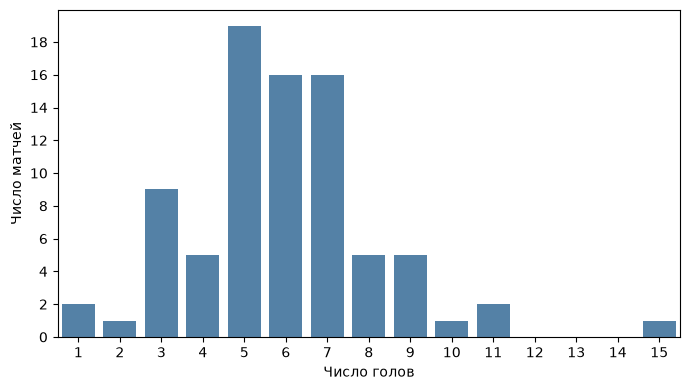

In [17]:
plt.figure(figsize=(7, 4))
sns.countplot(x="Total Score", data=games, color="steelblue",
              order=range(games["Total Score"].min(), games["Total Score"].max() + 1))
plt.xlabel("Число голов")
plt.ylabel("Число матчей")

plt.gca().xaxis.set_major_locator(ticker.MultipleLocator(1))
plt.gca().yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

Распределение одномодальное, мода - 5 голов (19 матчей). На центральные значения 5–7 голов приходится 51 матч из 82, а на диапазон 4–7 голов - около двух третей всех игр. Распределение слегка скошено вправо - есть единичные игры с 9–11 голами и один выброс в 15 голов (Colorado - Minnesota, 9–6). Слева распределение ограничено: в плей-офф нет ничьих, поэтому минимум 1 гол (две игры).

# 6.

In [18]:
sorted_games = games.sort_values("Total Score")

print("Топ-3 самых нерезультативных матчей:")
for i in sorted_games.index[:3]:
    print(gameInfo(i))

print()

print("Топ-3 самых результативных матчей:")
for i in sorted_games.index[-3:][::-1]:
    print(gameInfo(i))

Топ-3 самых нерезультативных матчей:
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Carolina Hurricanes - Ottawa Senators (2 - 0, Final, 2026-04-18)

Топ-3 самых результативных матчей:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)
Anaheim Ducks - Edmonton Oilers (7 - 4, Final, 2026-04-24)
Montréal Canadiens - Buffalo Sabres (3 - 8, Final, 2026-05-16)


Так самый результативный матч (Colorado Avalanche - Minnesota Wild) закончился с 15 голами, самый нерезультативный (Philadelphia Flyers - Pittsburgh Penguins и Montréal Canadiens - Tampa Bay Lightning) - с 1 голом

# 7.

In [19]:
events['Player in the Event #1'].unique() # есть nan, не буду учитывать

<ArrowStringArray>
[                  nan,         'Pavel Zacha',           'Alex Tuch',
       'Tage Thompson',        'Peyton Krebs',      'Elias Lindholm',
           'Josh Doan',       'Fraser Minten',        'Mason Lohrei',
       'Logan Stanley',
 ...
    'William Karlsson',          'Ben Hutton',       'Ross Johnston',
      'Jansen Harkins',       'Dylan Coghlan',      'Olen Zellweger',
        'Brandon Saad', 'Mackenzie Blackwood',       'Brandon Bussi',
      'Braeden Bowman']
Length: 364, dtype: str

In [20]:
player_cols_away = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)]
player_cols_home = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)]
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]

all_player_cols = player_cols_away + player_cols_home + goalie_cols

def count_players(group):
    players = set()
    for col in all_player_cols:
        players.update(group[col].dropna().unique())
    return len(players)

player_count = events.groupby('Game ID').apply(count_players).rename('Player Count')

player_count_df = pd.DataFrame({
    'Game Info': [gameInfo(g) for g in player_count.index],
    'Player Count': player_count.values
}, index=player_count.index)

player_count_df.sort_values('Player Count', ascending=False).head()

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40
2025030215,"Buffalo Sabres - Montréal Canadiens (3 - 6, Fi...",39
2025030243,"Anaheim Ducks - Vegas Golden Knights (2 - 6, F...",39
2025030233,"Minnesota Wild - Colorado Avalanche (5 - 1, Fi...",39
2025030235,"Colorado Avalanche - Minnesota Wild (4 - 3, Fi...",39


In [21]:
player_count_df.sort_values('Player Count', ascending=False).head(1)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


В игре Montréal Canadiens - Buffalo Sabres с наибольшим числом игроков сыграло 40 игроков.

# 8.

In [22]:
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()

shots['is_home'] = shots['Team Making the Play'] == shots['Home Team']

def goal_x(row):
    side = row["Home Team's Defending Side"]
    if side == 'left':
        return -89 if not row['is_home'] else 89
    else:
        return 89 if not row['is_home'] else -89

shots['Goal X'] = shots.apply(goal_x, axis=1)

def distance_to_goal(x, y, X):
    if y < -3:
        return np.sqrt((x - X)**2 + (y + 3)**2)
    elif y <= 3:
        return abs(x - X)
    else:
        return np.sqrt((x - X)**2 + (y - 3)**2)

shots['Shot Length'] = shots.apply(lambda r: distance_to_goal(r['X Coordinate on the Ice Rink'],
                               r['Y Coordinate on the Ice Rink'],
                               r['Goal X']),
                                   axis=1)

shots[['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


In [23]:
shots['Shot Length'].describe()

count    7266.000000
mean       35.408858
std        27.470981
min         0.000000
25%        15.556349
50%        31.898275
75%        47.877446
max       188.215302
Name: Shot Length, dtype: float64

В датасете 7266 ударов. В среднем расстояние удара - 35, медиана - 32. При этом минимальное расстояние - 0 (у самых ворот). максимальное - 188. Q1-Q3 - удары в расстоянии от 16 до 48.

# 9.

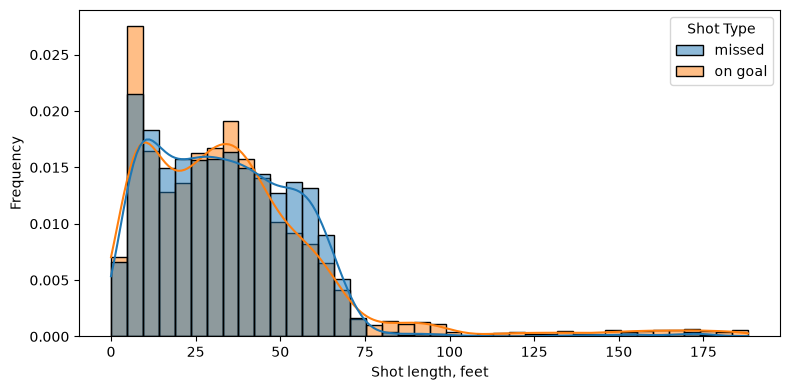

In [24]:
shots['Shot Type'] = shots['Play Type'].apply(lambda t: 'on goal' if t in ['goal', 'shot-on-goal'] else 'missed')

plt.figure(figsize=(8, 4))
sns.histplot(data=shots, x='Shot Length', hue='Shot Type',stat='density', common_norm=False, bins=40, alpha=0.5, kde = True)

plt.xlabel('Shot length, feet')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Распределения похожи. Оба распределения имеют моду в районе 10 футов. По всей видимости на попадание влияет не столько расстояние, сколько препятствующих игроков по траектории удара.
Точные броски имеют более длинный правый хвост. Возможно удар с длинной дистанции производится тогда, когда бьющий максимально уверен в ударе (когда вратаря нет на месте и тп.), что приводит к длинному хвосту.

# 10. 

In [25]:
unblocked = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()

counts = unblocked.groupby(['Game ID', 'Team Making the Play', 'Play Type']).size().unstack(fill_value=0)

counts['Share of Shots on Goal'] = (counts.get('shot-on-goal', 0) + counts.get('goal', 0)) / \
                                   (counts.get('shot-on-goal', 0) + counts.get('goal', 0) + counts.get('missed-shot', 0))

numshots = counts['Share of Shots on Goal']
numshots

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64

In [26]:
numshots.describe()

count    164.000000
mean       0.639150
std        0.085000
min        0.352941
25%        0.582955
50%        0.638889
75%        0.688889
max        0.860465
Name: Share of Shots on Goal, dtype: float64

в среднем 64% незаблокированных ворот достигают ворот. От команды к команде это число различается (минимальный показатель - 35%, максимальный - 86%). Такие различия могут быть как из-за стиля команды, так и из-за класса самой команды.

# 11.

In [27]:
avg_share = numshots.groupby('Team Making the Play').mean()


print("Топ-5:", avg_share.nlargest(5))
print("")
print("\nХудшие 5:", avg_share.nsmallest(5))

Топ-5: Team Making the Play
Edmonton Oilers        0.706232
Philadelphia Flyers    0.683668
Dallas Stars           0.670142
Minnesota Wild         0.656099
Colorado Avalanche     0.652559
Name: Share of Shots on Goal, dtype: float64


Худшие 5: Team Making the Play
Pittsburgh Penguins    0.554046
Utah Mammoth           0.599298
Carolina Hurricanes    0.614844
Tampa Bay Lightning    0.625713
Buffalo Sabres         0.625838
Name: Share of Shots on Goal, dtype: float64


Команда Edmonton Oilers лидируют по точности бросков (~70.6%). Вероятно много ударов с близких позиций.
Pittsburgh Penguins самые неточные (~55.4%), много промахов. Возможно бьют дальше от ворот.
Разброс ~15 процентных пунктов между лучшей и худшей командой — заметная разница в стиле атаки.

# 12.

In [28]:
sog = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]

games_per_team = pd.concat([
    games['Away Team'], games['Home Team']
]).value_counts()

sog_counts = sog.groupby('Team Making the Play').size()
goal_counts = events[events['Play Type'] == 'goal'].groupby('Team Making the Play').size()

avgshots = pd.DataFrame({
    'Shot': sog_counts / games_per_team,
    'Goal': goal_counts / games_per_team
})
avgshots.index.name = 'Team Making the Play'
print(avgshots)

                           Shot      Goal
Team Making the Play                     
Anaheim Ducks         31.666667  3.250000
Boston Bruins         25.166667  2.000000
Buffalo Sabres        30.461538  3.307692
Carolina Hurricanes   31.631579  3.473684
Colorado Avalanche    32.153846  3.384615
Dallas Stars          31.000000  2.500000
Edmonton Oilers       28.333333  3.500000
Los Angeles Kings     25.250000  1.250000
Minnesota Wild        28.727273  3.727273
Montréal Canadiens    23.263158  2.842105
Ottawa Senators       27.500000  1.250000
Philadelphia Flyers   24.600000  2.100000
Pittsburgh Penguins   26.500000  1.833333
Tampa Bay Lightning   28.000000  2.142857
Utah Mammoth          27.833333  3.000000
Vegas Golden Knights  26.545455  3.454545


Количество бросков и голов не всегда связано напрямую. Например, Montreal бросает меньше всех (23,3), но забивает 2,84 гола - больше, чем Dallas (2,50), который бросает 31 раз. Если смотреть на реализацию (сколько голов приходится на броски), то у Minnesota и Vegas это около 13%, у Edmonton и Montreal - около 12%, а у Ottawa всего 4,5%, у Los Angeles - 5%. Значит, на результат влияет не только число бросков, но и то, насколько они опасны, а также игра вратарей.

# 13.

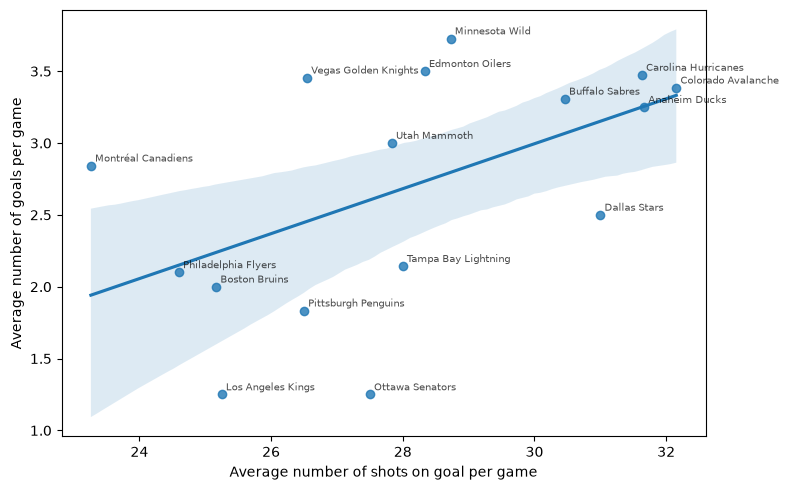

In [29]:
plt.figure(figsize=(8, 5))
sns.regplot(data=avgshots, x='Shot', y='Goal')
plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')

for team, row in avgshots.iterrows():
    plt.annotate(team, (row['Shot'], row['Goal']),
                 fontsize=7, alpha=0.7,
                 xytext=(3, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

Видна положительная связь между средним числом бросков за игру и средним количеством голов. Команды с более агрессивным стилем забивают больше голов. При этом доверительный интервал достаточно широкий, что говорит о том, что реальный наклон для команд может варьироваться в этих пределах.

# 14.

In [30]:
all_shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'])]
shots_per_game = all_shots.groupby('Game ID').size()
idxmax = shots_per_game.idxmax()

print(gameInfo(idxmax))
print("Всего ударов:", shots_per_game.max())

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Всего ударов: 208


# 15.

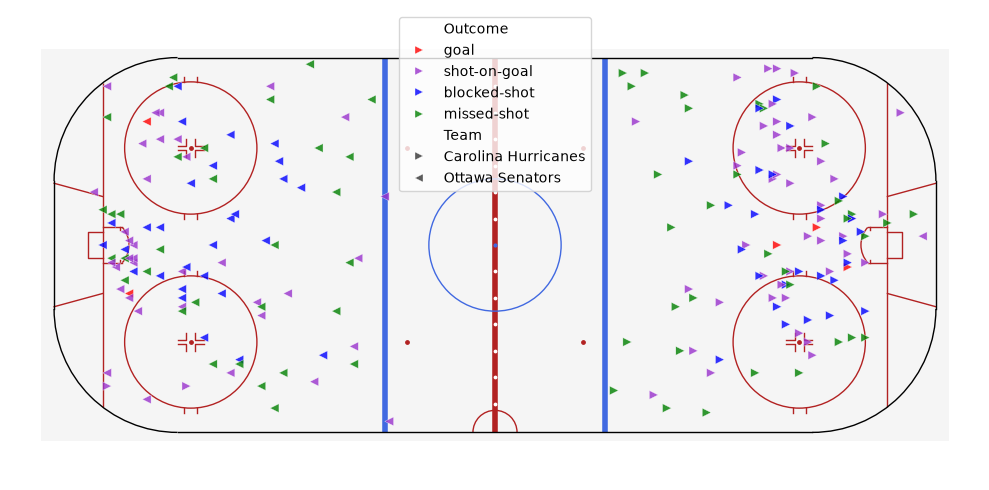

In [31]:
import seaborn as sns

game_id = idxmax
game_shots = all_shots[all_shots['Game ID'] == game_id].copy()

# переворот координат в нечётных периодах
odd = game_shots['Period'] % 2 == 1
game_shots['x_plot'] = np.where(odd, -game_shots['X Coordinate on the Ice Rink'],
                                      game_shots['X Coordinate on the Ice Rink'])
game_shots['y_plot'] = np.where(odd, -game_shots['Y Coordinate on the Ice Rink'],
                                      game_shots['Y Coordinate on the Ice Rink'])

# столбцы с нужными для легенды названиями
game_shots['Outcome'] = game_shots['Play Type']
game_shots['Team'] = game_shots['Team Making the Play']

home = game_shots['Home Team'].iloc[0]
away = game_shots['Away Team'].iloc[0]

plt.figure(figsize=(10, 5))
plot_rink(False)

sns.scatterplot(
    data=game_shots, x='x_plot', y='y_plot',
    hue='Outcome', hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
    palette={'goal': 'red', 'shot-on-goal': 'darkorchid',
             'blocked-shot': 'blue', 'missed-shot': 'green'},
    style='Team', markers={home: '>', away: '<'},   # хозяева смотрят вправо, гости влево
    s=40, alpha=0.8, linewidth=0.3
)

plt.legend(loc='upper center')
plt.axis('equal')
plt.axis('off')
plt.tight_layout()
plt.show()

На схеме видно, что большая часть ударов находится в зоне нападения - за красной и синей линиями.

# 16.

In [32]:
goals = events[events['Play Type'] == 'goal']
top_scorers = goals['Player in the Event #1'].value_counts().head(10)
print('Cписок из десяти игроков, которые забили больше всех голов в плейофф:')
top_scorers

Cписок из десяти игроков, которые забили больше всех голов в плейофф:


Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Alex Newhook         7
Taylor Hall          7
Jackson Blake        7
Nathan MacKinnon     7
Name: count, dtype: int64

Больше всех в плей-офф забил Brett Howden - 14 голов. Второе и третье места у Pavel Dorofeyev (12) и Logan Stankoven (11). У Mitch Marner 10 шайб, потом идут сразу несколько игроков с 8 голами (Nikolaj Ehlers, Jordan Staal), и группа из четырех человек с 7 голами (Newhook, Hall, Blake, MacKinnon).

# 17.

In [33]:
assists = pd.concat([
    goals['Player in the Event #2'],
    goals['Player in the Event #3']
]).dropna()

top_assists = assists.value_counts().head(10)
print('Cписок из десяти игроков, которые набрали больше всех голевых передач в плей-офф:')
print(top_assists)

Cписок из десяти игроков, которые набрали больше всех голевых передач в плей-офф:
Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: count, dtype: int64


Лучшим распасовщиком стал Jack Eichel (20 передач), совсем немного ему уступает Mitch Marner (19). Остальные игроки из топ-10 идут гораздо плотнее - у Lane Hutson и Jackson Blake по 13, а у Nick Suzuki, Taylor Hall, Martin Necas и Shea Theodore — по 12. В конце - Kirill Kaprizov и Quinn Hughes с 11.

# 18.

In [34]:
goals_count = goals['Player in the Event #1'].value_counts()

assists_count = assists.value_counts()

points = goals_count.add(assists_count, fill_value=0).astype(int)
top_points = points.sort_values(ascending=False).head(10)

print('Cписок из десяти игроков, которые набрали больше всего очков по системе гол плюс пас:')
print(top_points)

Cписок из десяти игроков, которые набрали больше всего очков по системе гол плюс пас:
Player in the Event #1
Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Pavel Dorofeyev    16
Lane Hutson        16
Logan Stankoven    16
Name: count, dtype: int64


Первое место по очкам (гол+пас) занимает Mitch Marner с 29 баллами, далее с 20+ Jack Eichel (22) и Jackson Blake (20). Затем результаты идут довольно плотно - Taylor Hall набрал 19 очков, а сразу три игрока (Howden, Ehlers, Theodore) - по 18. В конце списка Dorofeyev, Hutson и Stankoven с 16 очками каждый.

# 19.

In [35]:
long = events[['Game ID'] + all_player_cols].melt(id_vars='Game ID', value_name='Player')
long = long.dropna(subset=['Player'])
games_played = long.drop_duplicates(['Game ID', 'Player']).groupby('Player').size()

sog = events[events['Play Type'].isin(['shot-on-goal', 'goal'])]
sog_per_player = sog['Player in the Event #1'].value_counts()

avg_sog = (sog_per_player / games_played).dropna()
top_avg_sog = avg_sog.sort_values(ascending=False).head(10)

print('Десять игроков с наибольшим средним числом бросков в створ за игру:')
print(top_avg_sog)

Десять игроков с наибольшим средним числом бросков в створ за игру:
Player in the Event #1
Jason Robertson     5.000000
Dylan Guenther      4.500000
Nikita Kucherov     4.428571
Matt Boldy          4.363636
Quinton Byfield     4.250000
Darren Raddysh      4.000000
Joel Eriksson Ek    4.000000
Alex Laferriere     3.750000
David Pastrnak      3.666667
Nathan MacKinnon    3.615385
dtype: float64


Список самых бросающих игроков возглавляет Jason Robertson - в среднем ровно 5 бросков в створ за игру. Далее идут Dylan Guenther (4.5) и Nikita Kucherov (4.43). Остальные семь игроков из топ-10 расположились в диапазоне от 3.6 до 4.36 броска за матч.

# 20.

In [36]:
hits = events[events['Play Type'] == 'hit']
hits_per_player = hits['Player in the Event #1'].value_counts()

avg_hits = (hits_per_player / games_played).dropna()
top_avg_hits = avg_hits.sort_values(ascending=False).head(10)

print('Десять игроков с наибольшим средним числом силовых приёмов за игру:')
print(top_avg_hits)

Десять игроков с наибольшим средним числом силовых приёмов за игру:
Player in the Event #1
Lawson Crouse         6.333333
Alex Turcotte         6.000000
Alexander Petrovic    6.000000
Yakov Trenin          5.666667
Dylan Cozens          5.500000
Vasily Podkolzin      5.333333
Marcus Foligno        5.000000
Ivan Barbashev        5.000000
Carl Grundstrom       5.000000
Owen Tippett          4.833333
dtype: float64


Первое место у Lawson Crouse (6.33 приема за игру), следом идут Alex Turcotte и Alexander Petrovic (по 6.0). Замыкает десятку Owen Tippett с показателем 4.83. Видно, что лидеры отрываются не сильно - плотность результатов в первой десятке довольно высокая, большинство игроков держится в диапазоне 5-6 силовых приемов за игру.

# 21.

In [37]:
goalies_games = pd.concat([
    events[['Game ID', "Away Team's Goalie"]].rename(columns={"Away Team's Goalie": 'Goalie'}),
    events[['Game ID', "Home Team's Goalie"]].rename(columns={"Home Team's Goalie": 'Goalie'}),
]).dropna().drop_duplicates()

g = events[events['Play Type'] == 'goal'].copy()
g['Goalie'] = np.where(g['Team Making the Play'] == g['Away Team'],
                       g["Home Team's Goalie"], g["Away Team's Goalie"])

ga = g.dropna(subset=['Goalie']).groupby(['Game ID', 'Goalie']).size().rename('GA')

res = goalies_games.merge(ga.reset_index(), on=['Game ID', 'Goalie'], how='left').fillna({'GA': 0})

shutouts = (res[res['GA'] == 0]
            .groupby('Goalie').size()
            .sort_values(ascending=False)
            .rename('Матчей без пропущенных'))

shutouts.to_frame()

,Матчей без пропущенных
Goalie,
Frederik Andersen,3
Brandon Bussi,2
Dan Vladar,2
Andrei Vasilevskiy,1
Arturs Silovs,1
Jakub Dobes,1
Joonas Korpisalo,1
Scott Wedgewood,1


В плей-офф больше всех сухих матчей у Frederik Andersen - 3 игры без пропущенных шайб. У Brandon Bussi и Dan Vladar по 2 таких матча. Еще пять вратарей (Vasilevskiy, Silovs, Dobes, Korpisalo и Wedgewood) сыграли на ноль по одному разу. В целом это довольно редкое явление.

# 22.

Какая команда чаще всего побеждала, забрасывая первой шайбу в матче?

In [38]:
first_goals = events[events['Play Type'] == 'goal'].sort_values('Play ID').groupby('Game ID').first()
first_goals = first_goals[['Team Making the Play', 'Home Team', 'Away Team']]

def winner(row):
    if row['Home Score'] > row['Away Score']:
        return row['Home Team']
    elif row['Away Score'] > row['Home Score']:
        return row['Away Team']
    else:
        return None

games['Winner'] = games.apply(winner, axis=1)

first_goals = first_goals.join(games[['Winner']], how='inner')

first_goals['FirstGoalWon'] = first_goals['Team Making the Play'] == first_goals['Winner']

share = first_goals['FirstGoalWon'].mean()
print(f"Доля игр, где команда, забившая первой, победила: {share:.2%}")

by_team = first_goals.groupby('Team Making the Play')['FirstGoalWon'].agg(['count', 'sum', 'mean'])
by_team = by_team.sort_values('count', ascending=False)
print(by_team)

Доля игр, где команда, забившая первой, победила: 68.29%
                      count  sum      mean
Team Making the Play                      
Carolina Hurricanes      14   12  0.857143
Vegas Golden Knights     11    8  0.727273
Buffalo Sabres            8    5  0.625000
Colorado Avalanche        7    5  0.714286
Montréal Canadiens        7    6  0.857143
Minnesota Wild            6    4  0.666667
Edmonton Oilers           5    2  0.400000
Philadelphia Flyers       5    3  0.600000
Anaheim Ducks             4    3  0.750000
Boston Bruins             3    1  0.333333
Dallas Stars              3    2  0.666667
Pittsburgh Penguins       3    2  0.666667
Utah Mammoth              3    1  0.333333
Tampa Bay Lightning       2    2  1.000000
Los Angeles Kings         1    0  0.000000


В плей-офф команда, которая забивает первой, побеждает в 68% случаев. Лучшая конвертация у Carolina Hurricanes (86%) и Montréal Canadiens (86%).